# D05 — Hf-Nd isotope terrane mapping

**Cluster D: Zircons + tectonic-setting predictors.**

Hf and Nd isotopes are the workhorse tracers for classifying continental crust as either **juvenile** — freshly extracted from the mantle — or **evolved** — reworked from older crustal material. εHf(t) and εNd(t) values close to zero (chondritic) or positive indicate juvenile crust; strongly negative values indicate evolved crust that has spent significant time as continental material before being re-melted. The two-stage depleted-mantle model age T_DM2 estimates when the crust in question was originally extracted from the mantle. Mapping these quantities across a continent yields a **crustal architecture map**: a spatial view of when each terrane was born and how much it has been reworked since.

This is the workflow pioneered with Nd isotopes by Bennett & DePaolo (1987) for the western USA, and applied with Hf-in-zircon compilations by Belousova et al. (2010) and Roberts & Spencer (2015).

The data are the global databases of Puetz, Spencer, Condie & Roberts (2024): **about 210,000 Lu-Hf analyses of zircon** from 7,061 samples and **22,019 whole-rock Sm-Nd analyses**, each with sample coordinates and with εHf(t), εNd(t) and model ages recalculated by the authors with one set of constants.

## What this notebook produces

1. **§3 — Present-day εHf(t) map of igneous samples.** The 3,266 igneous samples of the Hf database at their present-day coordinates, each coloured by the median εHf(t) of its zircons (red = evolved, blue = juvenile).
2. **§4 — Nd model-age map.** The whole-rock samples coloured by their two-stage depleted-mantle model age T_DM2(Nd) — the Bennett & DePaolo (1987) terrane-mapping quantity.
3. **§5 — Paleogeographic reconstruction for one window.** Igneous samples with crystallisation ages in a chosen window (default 500-700 Ma) on the Cao 2024 reconstruction at 600 Ma, coloured by εHf(t).
4. **§6 — Global Hf evolution diagram.** εHf(t) against U-Pb age for all 210,000 zircons, with the CHUR and depleted-mantle evolution lines.

## Learning objectives

- Load a large isotope compilation and reduce it to one value per sample (the median of its zircons).
- Colour a map by a continuous isotopic quantity with a diverging colour scale.
- Reconstruct point samples to a common age on a deep-time plate model (Cao 2024, 0-1.8 Ga).
- Place a whole database on the εHf-age evolution diagram.

## Prerequisites and runtime

- **Plate model**: Cao 2024 (0-1800 Ma), as in D01-D04.
- **Data**: `data/hf_nd_isotopes/` (3.1 MB), built from Puetz et al. (2024) by `tools/build_hf_nd_puetz2024.py`.
- **Python**: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`.
- **Runtime**: \~1 minute.


## Environment + imports


In [1]:
from pathlib import Path
import os, sys
if Path("../data").exists() and not Path("data").exists():
    os.chdir("..")

import numpy as np
import pandas as pd
import pygmt
import gplately
import pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable

print("Environment")
print(f"  python      {sys.version.split()[0]}")
for _m in (np, pd, pygmt, gplately, pygplates):
    print(f"  {_m.__name__:11s} {getattr(_m, '__version__', 'n/a')}")


Environment
  python      3.13.18
  numpy       2.5.3
  pandas      3.0.5
  pygmt       v0.19.0
  gplately    2.0.0
  pygplates   1.0.0


In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME              = "Cao2024"  # 0-1.8 Ga coverage — matches D01-D04 zircon workflow
ANCHOR_PLATE_ID         = 0                    # Cao 2024 default anchor

# The paleogeographic reconstruction in §5 shows igneous samples with crystallisation ages
# inside this window, on the continents of PALEO_TARGET_MA. Default: 500-700 Ma, the
# Neoproterozoic-Cambrian assembly of Gondwana.
PALEO_WINDOW_MIN_MA     = 500
PALEO_WINDOW_MAX_MA     = 700
PALEO_TARGET_MA         = 600                  # continents drawn at this age

# Colour ranges
EPS_HF_RANGE            = [-10, 10, 1]         # symmetric around CHUR
T_DM_RANGE_MA           = [0, 4000, 100]       # crustal-formation-age domain

# Puetz et al. (2024) Lu-Hf zircon and Sm-Nd whole-rock databases
DATA_DIR                = Path("data/hf_nd_isotopes")
HF_SAMPLES_CSV          = DATA_DIR / "hf_zircon_samples.csv.gz"   # one row per sample (grain medians)
HF_GRAINS_CSV           = DATA_DIR / "hf_zircon_grains.csv.gz"    # one row per zircon analysis
ND_CSV                  = DATA_DIR / "nd_whole_rock.csv.gz"       # one row per whole-rock analysis

# CHUR + DM reference-line values (Bouvier et al. 2008 for CHUR;
# Griffin et al. 2000 for depleted-mantle-Hf reference)
LAMBDA_176LU            = 1.867e-11            # per year
CHUR_176HF_177HF_TODAY  = 0.282785
CHUR_176LU_177HF_TODAY  = 0.0336
DM_176HF_177HF_TODAY    = 0.28325
DM_176LU_177HF_TODAY    = 0.0388
# ============================================================================
print(f"  model:        {MODEL_NAME}")
print(f"  paleo target: {PALEO_TARGET_MA} Ma")
print(f"  age window:   {PALEO_WINDOW_MIN_MA}-{PALEO_WINDOW_MAX_MA} Ma")

  model:        Cao2024
  paleo target: 600 Ma
  age window:   500-700 Ma


## 1. Load the compilation

Three tables: the Hf samples (one row per sample, with the medians of its zircons), the individual Hf analyses, and the whole-rock Nd analyses. The sample medians characterise an **igneous** sample, whose zircons crystallised together; a detrital sample mixes grains of many sources, so §3 and §5 use the igneous samples only, and the detrital grains appear in §6.


In [3]:
hf_samples = pd.read_csv(HF_SAMPLES_CSV, comment="#")
grains     = pd.read_csv(HF_GRAINS_CSV, comment="#")
nd         = pd.read_csv(ND_CSV, comment="#")

df = hf_samples[hf_samples["rock_class"] == "igneous"].reset_index(drop=True)
print(f"  Hf:  {len(grains):,} zircon analyses from {len(hf_samples):,} samples; {len(df):,} igneous samples")
print(f"       igneous ages {df['age_ma'].min():.0f}-{df['age_ma'].max():.0f} Ma, "
      f"median εHf(t) {df['eps_hf_t'].min():.1f} to {df['eps_hf_t'].max():.1f}")
print(f"  Nd:  {len(nd):,} whole-rock analyses, T_DM2 for {int(nd['tdm2_ma'].notna().sum()):,}, "
      f"εNd(t) {nd['eps_nd_t'].min():.1f} to {nd['eps_nd_t'].max():.1f}")
df[["sample_key", "country", "geol_unit", "rock_type", "n_grains", "age_ma", "eps_hf_t", "tdm2_ma"]].head()

  Hf:  210,064 zircon analyses from 7,061 samples; 3,266 igneous samples
       igneous ages 0-3964 Ma, median εHf(t) -53.8 to 16.9
  Nd:  22,019 whole-rock analyses, T_DM2 for 21,519, εNd(t) -40.8 to 18.3


,sample_key,country,geol_unit,rock_type,n_grains,age_ma,eps_hf_t,tdm2_ma
0,R10052-S00438,Western USA,North American Cordillera,granodiorite,3,1380.0,2.25,2000.0
1,R10052-S00439,Western USA,North American Cordillera,diorite,1,1705.0,7.52,1922.0
2,R10052-S00442,Western USA,North American Cordillera,granodiorite,1,1348.0,9.38,1529.0
3,R10052-S00443,Western USA,North American Cordillera,granodiorite,1,1760.0,0.22,2418.0
4,R10052-S00445,Western USA,North American Cordillera,granodiorite,2,1788.0,0.12,2446.0


## 2. Plate model


In [4]:
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="data/pmm_cache")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID,
)
gplot = gplately.PlotTopologies(
    plate_reconstruction=recon,
    coastlines=model.get_layer("Coastlines"),
    plot_engine=gplately.PygmtPlotEngine(),
    continents=model.get_layer("ContinentalPolygons"),
    time=PALEO_TARGET_MA,
    anchor_plate_id=ANCHOR_PLATE_ID,
)
print(f"  {MODEL_NAME} loaded")

# Present-day plate IDs of the igneous samples (point-in-polygon against the static polygons)
pts = gplately.Points(plate_reconstruction=recon, lons=df["lon"].values, lats=df["lat"].values,
                      time=0, anchor_plate_id=ANCHOR_PLATE_ID)
df["plate_id"] = np.asarray(pts.plate_id, dtype=int)
# ...and the age at which that static polygon begins: a sample can only be drawn at times the polygon exists
partitioner = pygplates.PlatePartitioner(model.get_static_polygons(), recon.rotation_model)
def polygon_begin(lon, lat):
    poly = partitioner.partition_point(pygplates.PointOnSphere(lat, lon))
    return np.nan if poly is None else float(poly.get_feature().get_valid_time()[0])
df["polygon_begin_ma"] = [polygon_begin(lo, la) for lo, la in zip(df["lon"], df["lat"])]
print(f"  plate IDs assigned to {len(df)} igneous samples ({int((df['plate_id'] == 0).sum())} outside the polygons)")

  Cao2024 loaded


  plate IDs assigned to 3266 igneous samples (0 outside the polygons)


## 3. Present-day εHf(t) map

Every igneous sample, coloured by the median εHf(t) of its zircons. Red = evolved (negative), blue = juvenile (positive), white = chondritic (0). The most extreme values are drawn last, so they stay visible where samples crowd together.


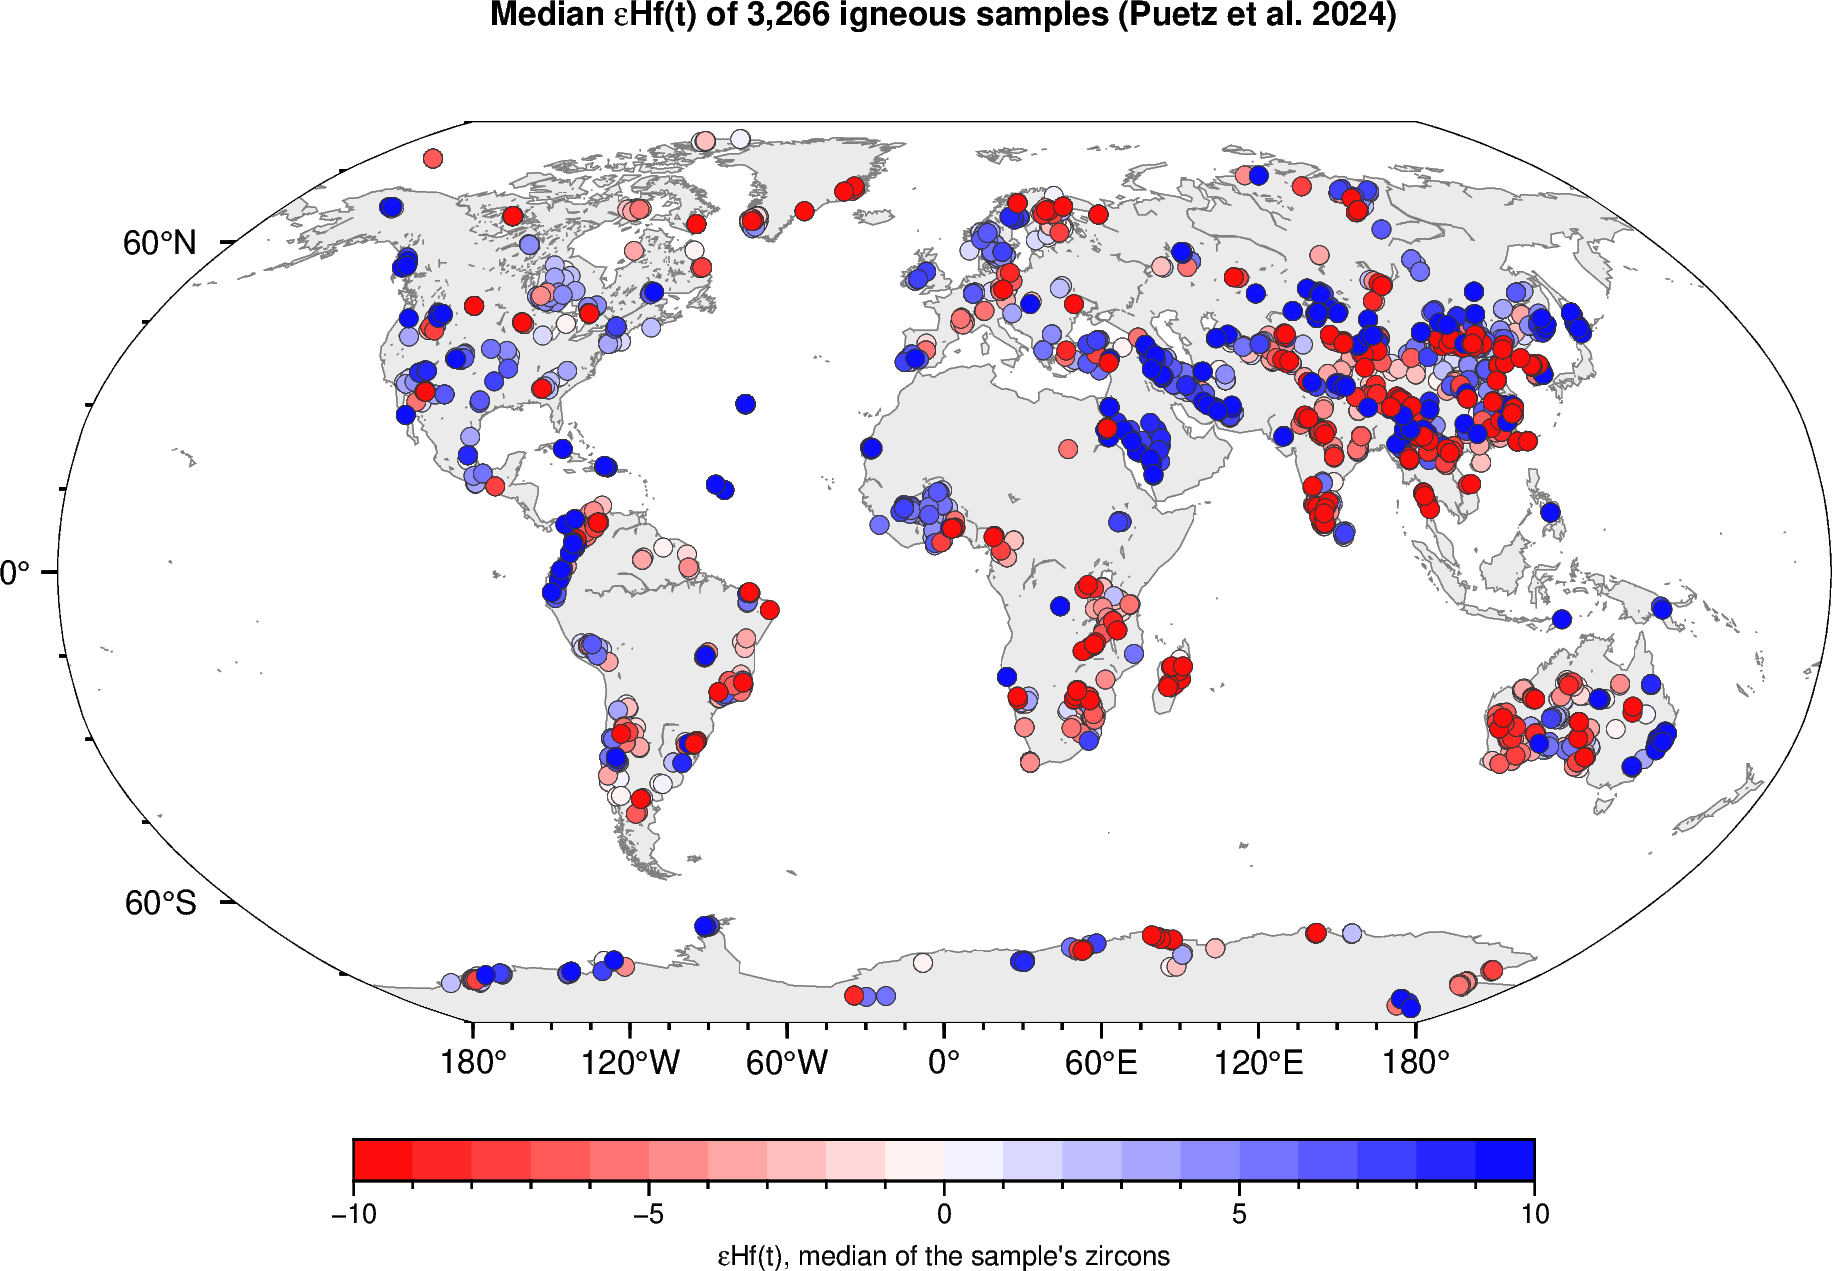

In [5]:
REGION, PROJ = [-180, 180, -90, 90], "N15c"
order = df["eps_hf_t"].abs().sort_values().index

fig = pygmt.Figure()
fig.basemap(region=REGION, projection=PROJ,
            frame=["af", f"+tMedian εHf(t) of {len(df):,} igneous samples (Puetz et al. 2024)"])
fig.coast(land="gray92", water="white", shorelines="0.25p,gray50")
pygmt.makecpt(cmap="polar", series=EPS_HF_RANGE, background="o", reverse=True)
fig.plot(x=df.loc[order, "lon"], y=df.loc[order, "lat"], style="c0.16c",
         fill=df.loc[order, "eps_hf_t"], cmap=True, pen="0.15p,gray20")
fig.colorbar(position="JBC+w10c/0.35c+h+o0/1c", frame=["a5f1", "x+lεHf(t), median of the sample's zircons"])
fig.show(width=1000)

### How to read this map

- **Red** — evolved crust, εHf(t) < 0: the zircons crystallised from melts of a source that had been separated from the depleted mantle long before — reworked older continental crust.
- **Blue** — juvenile crust, εHf(t) > 0: melts extracted from the depleted mantle shortly before the zircons crystallised, as in magmatic arcs.
- **White** — chondritic values: a mixture of juvenile and reworked sources, or crust only moderately older than its zircons.

The map reflects where the compiled studies sampled as well as the crust itself: East Asia, which dominates the database, is densely covered, while much of Africa, South America and Antarctica has few samples. Compare neighbouring samples rather than reading large blank areas.


## 4. Nd model-age map — the Bennett & DePaolo terrane view

The two-stage depleted-mantle model age T_DM2(Nd) is *when* the crustal source of a rock was extracted from the mantle — irrespective of when the rock itself formed. Two rocks of the same age can have very different T_DM2 if one formed from a juvenile melt and the other from re-melted old crust. Mapping T_DM2 defines **crustal-formation-age provinces** (Bennett & DePaolo 1987). Puetz et al. (2024) give T_DM2 as their preferred model age; the single-stage T_DM1 is not used.


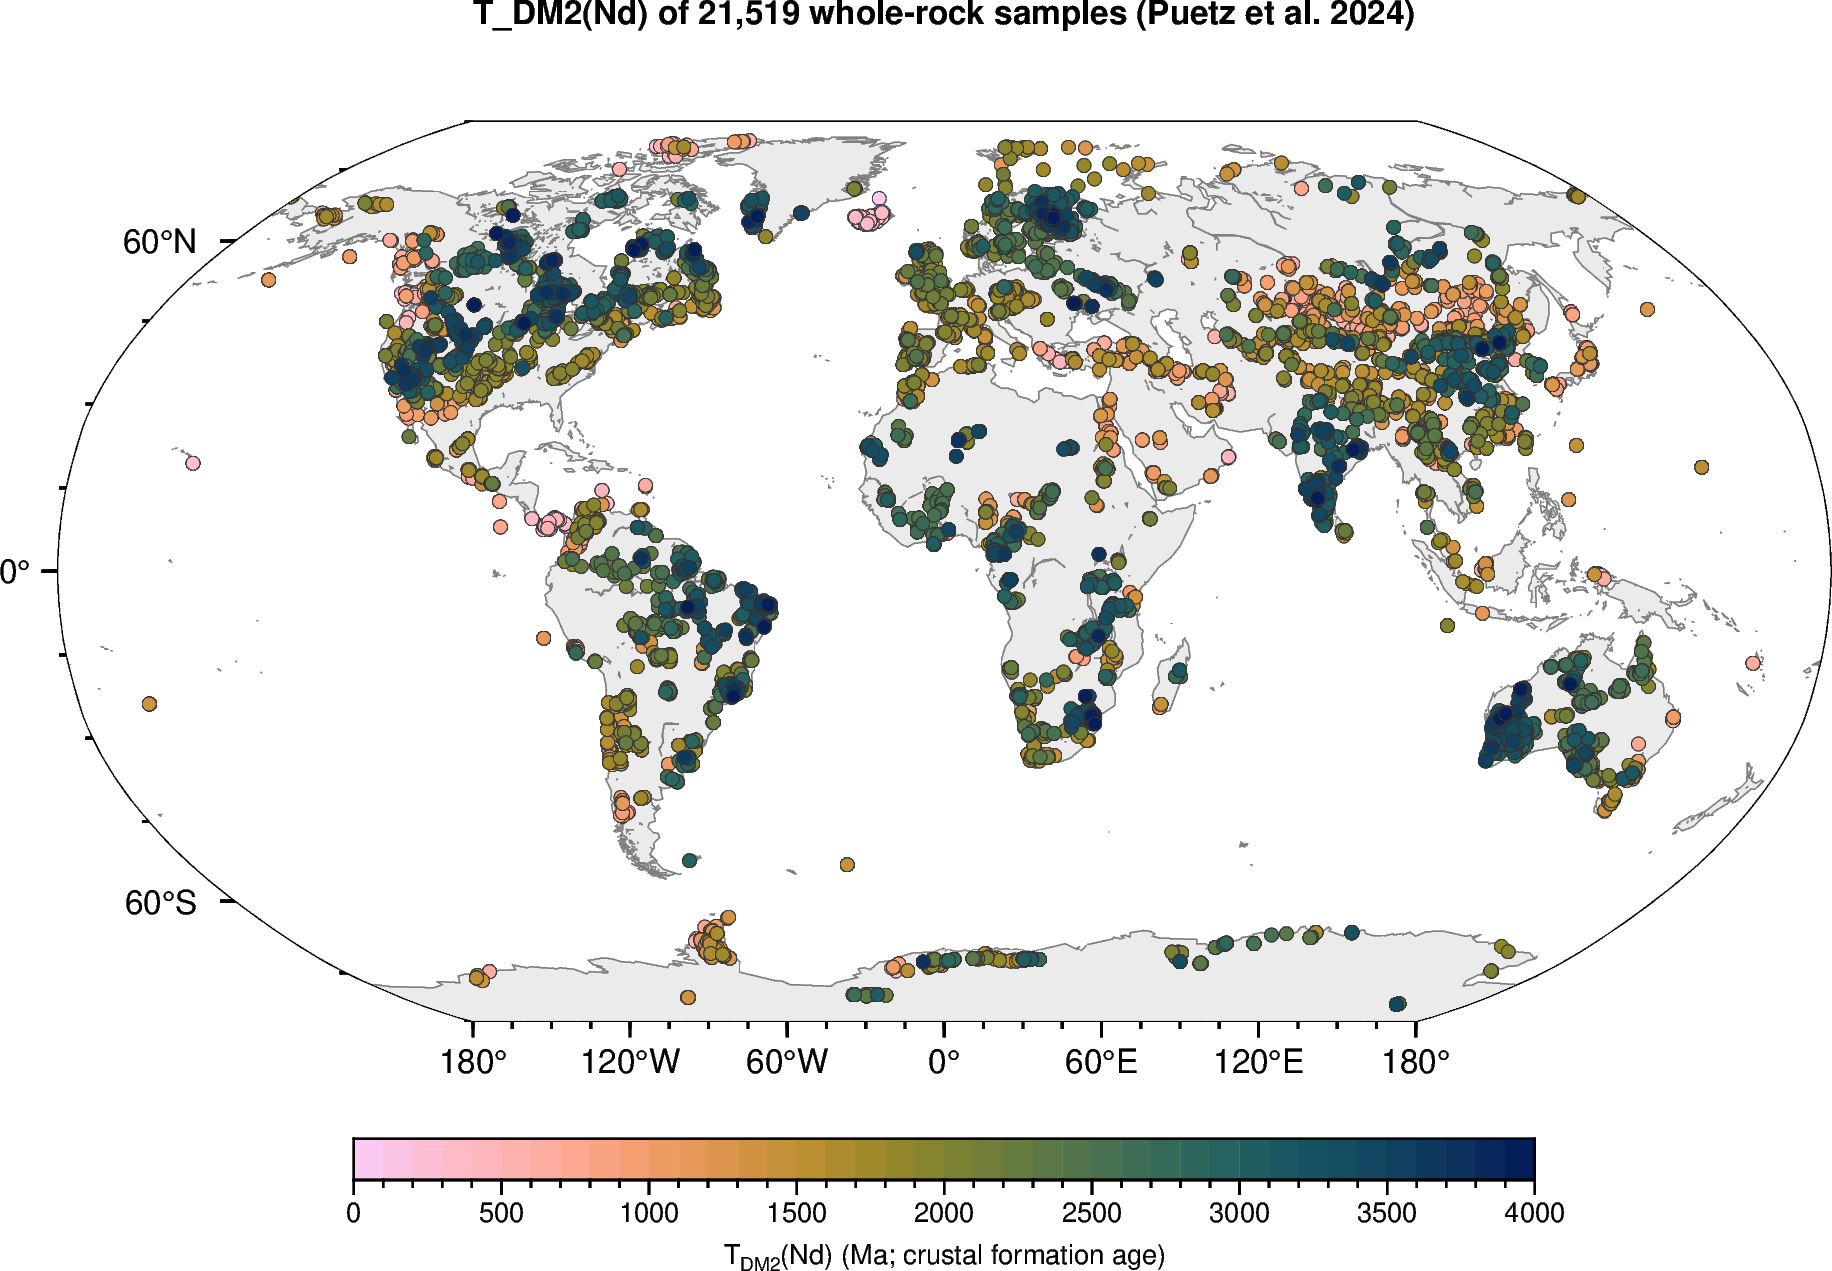

In [6]:
nd_map = nd.dropna(subset=["tdm2_ma"]).sort_values("tdm2_ma")   # oldest drawn last

fig = pygmt.Figure()
fig.basemap(region=REGION, projection=PROJ,
            frame=["af", f"+tT_DM2(Nd) of {len(nd_map):,} whole-rock samples (Puetz et al. 2024)"])
fig.coast(land="gray92", water="white", shorelines="0.25p,gray50")
pygmt.makecpt(cmap="batlow", series=T_DM_RANGE_MA, background="o", reverse=True)
fig.plot(x=nd_map["lon"], y=nd_map["lat"], style="c0.12c", fill=nd_map["tdm2_ma"], cmap=True,
         pen="0.1p,gray20")
fig.colorbar(position="JBC+w10c/0.35c+h+o0/1c", frame=["a500f100", "x+lT@-DM2@-(Nd) (Ma; crustal formation age)"])
fig.show(width=1000)

### How to read the T_DM2 map

- **Dark colours (T_DM2 > 3000 Ma)** — rocks derived from Archean crust: the cratonic cores.
- **Mid colours (T_DM2 \~1500-2500 Ma)** — Paleoproterozoic and Mesoproterozoic crust, or younger rocks with a large component of old crust.
- **Light colours (T_DM2 < 1000 Ma)** — Neoproterozoic and Phanerozoic juvenile crust, such as the Cordilleran arcs, the Central Asian Orogenic Belt and the Arabian-Nubian Shield.

Neighbouring samples with similar T_DM2 define a **crustal province** with a coherent history; sharp changes between them mark terrane boundaries.


## 5. Paleogeographic reconstruction for the chosen age window

Igneous samples with crystallisation ages (median zircon U-Pb age) in `[PALEO_WINDOW_MIN_MA, PALEO_WINDOW_MAX_MA]`, each rotated with its plate from its present position to `PALEO_TARGET_MA` and drawn on the continents of that age. Samples on plate polygons that only appear in the model after `PALEO_TARGET_MA` (younger accreted terranes) are left out. All samples go to the same age, so that they sit on the continents drawn; within a 200-Myr window that is an approximation for the samples far from the target age. Colour by εHf(t) shows where juvenile and reworked crust formed at that time.


  219 igneous samples with ages 500-700 Ma; 111 lie on plate polygons that exist at 600 Ma


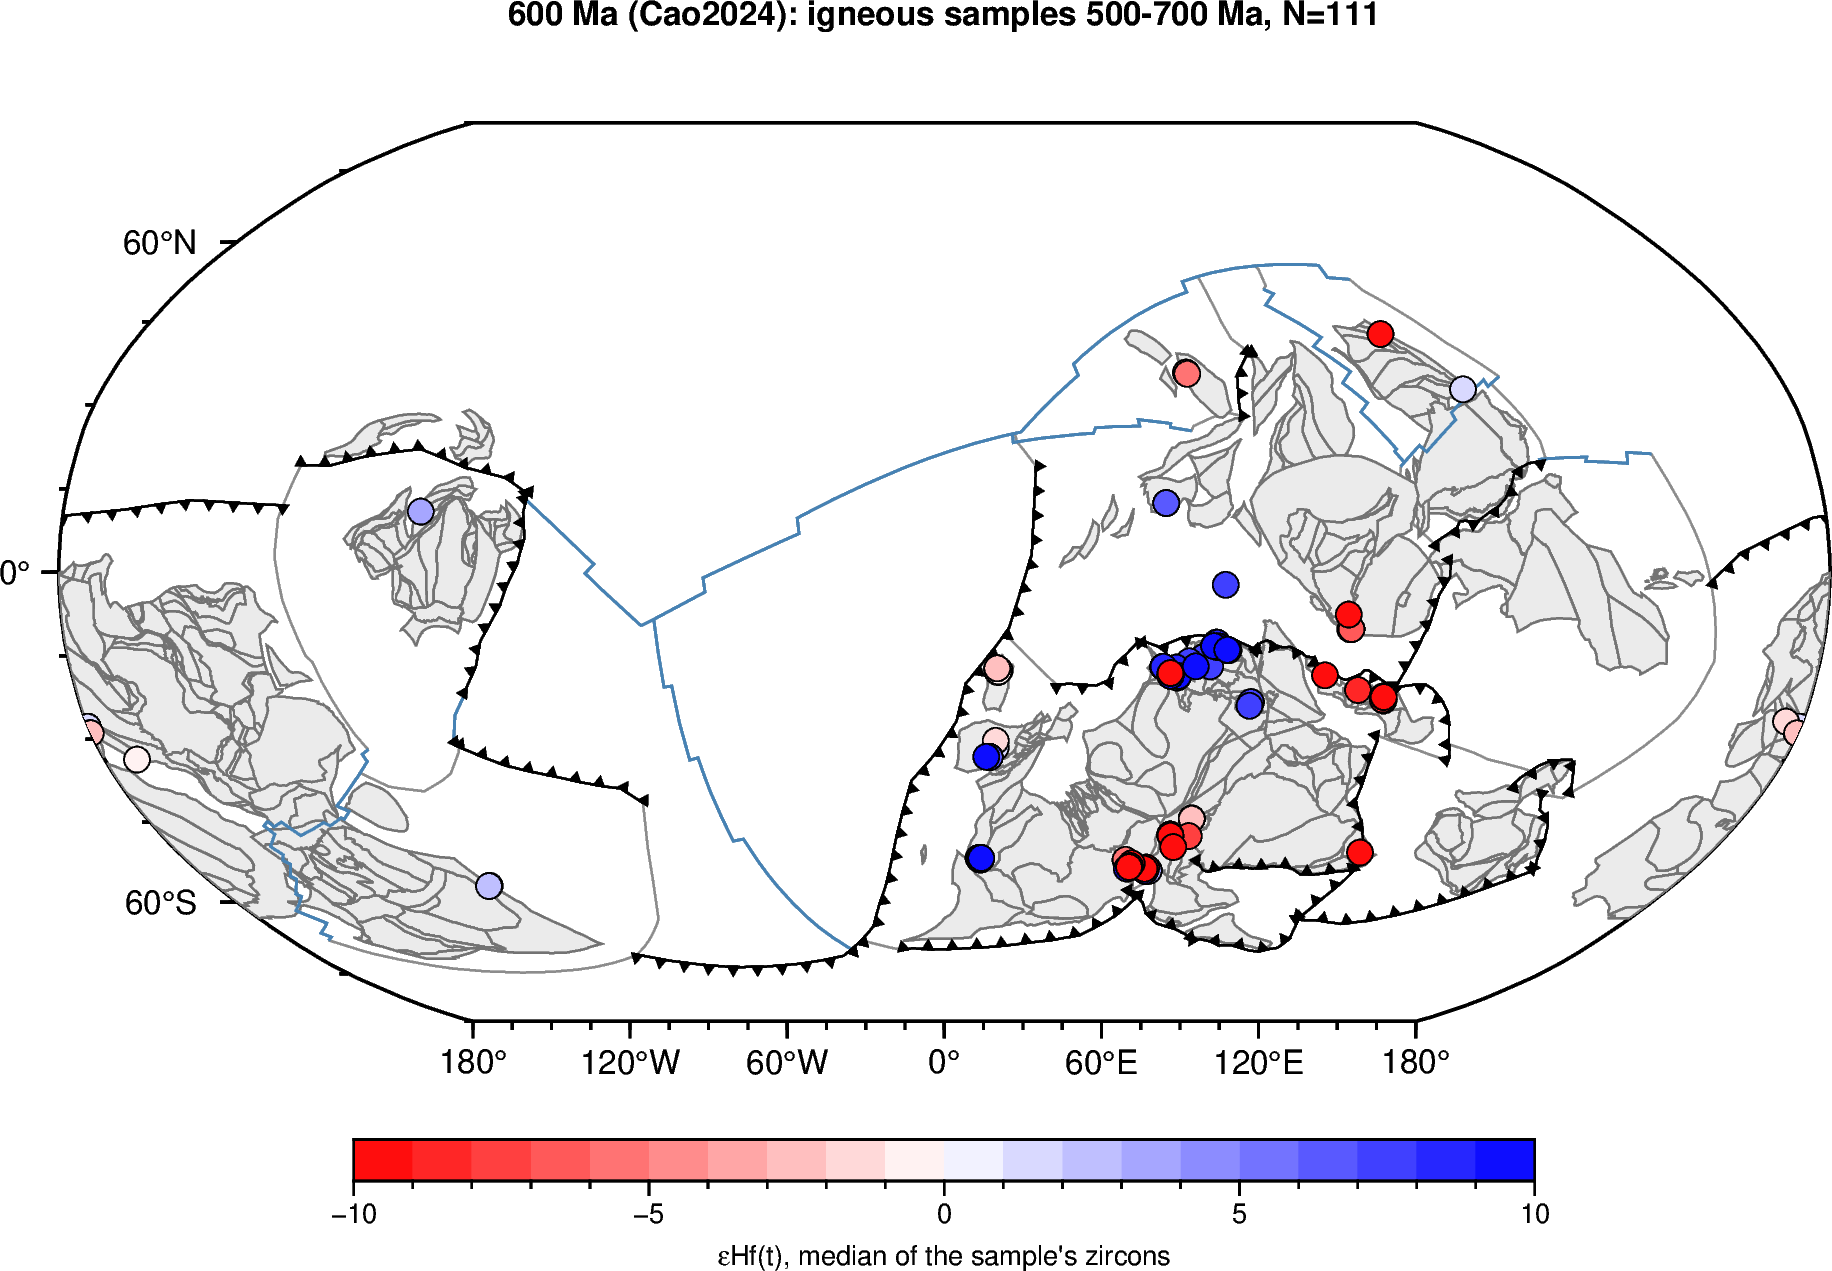

In [7]:
in_window = df["age_ma"].between(PALEO_WINDOW_MIN_MA, PALEO_WINDOW_MAX_MA)
window_df = df[in_window & (df["plate_id"] > 0) & (df["polygon_begin_ma"] >= PALEO_TARGET_MA)].copy()
print(f"  {int(in_window.sum())} igneous samples with ages {PALEO_WINDOW_MIN_MA}-{PALEO_WINDOW_MAX_MA} Ma; "
      f"{len(window_df)} lie on plate polygons that exist at {PALEO_TARGET_MA} Ma")

# Rotate every sample with its plate to PALEO_TARGET_MA
paleo = []
for lon, lat, pid in zip(window_df["lon"], window_df["lat"], window_df["plate_id"]):
    rot = recon.rotation_model.get_rotation(float(PALEO_TARGET_MA), int(pid), anchor_plate_id=ANCHOR_PLATE_ID)
    paleo.append((rot * pygplates.PointOnSphere(lat, lon)).to_lat_lon())
window_df["paleo_lat"], window_df["paleo_lon"] = np.array(paleo).T
window_df = window_df.loc[window_df["eps_hf_t"].abs().sort_values().index]

gplot.time = PALEO_TARGET_MA
fig = pygmt.Figure()
fig.basemap(region=REGION, projection=PROJ,
            frame=["af", f"+t{PALEO_TARGET_MA:.0f} Ma ({MODEL_NAME}): igneous samples "
                         f"{PALEO_WINDOW_MIN_MA}-{PALEO_WINDOW_MAX_MA} Ma, N={len(window_df)}"])
gplot.plot_all_topological_sections(fig, pen="0.5p,gray55")
gplot.plot_continents(fig, fill="gray92", pen="0.5p,gray45")
gplot.plot_ridges(fig, pen="0.6p,steelblue")
gplot.plot_subduction_teeth(fig, color="black")
pygmt.makecpt(cmap="polar", series=EPS_HF_RANGE, background="o", reverse=True)
fig.plot(x=window_df["paleo_lon"], y=window_df["paleo_lat"], style="c0.22c",
         fill=window_df["eps_hf_t"], cmap=True, pen="0.3p,black")
fig.colorbar(position="JBC+w10c/0.35c+h+o0/1c", frame=["a5f1", "x+lεHf(t), median of the sample's zircons"])
fig.show(width=1000)

### How to read the paleogeographic reconstruction

The map places the igneous rocks of 500-700 Ma on the continents of 600 Ma, during the assembly of Gondwana. Look for juvenile (blue) samples along the margins that faced subduction zones, such as the Arabian-Nubian Shield and the Central Asian belts, and for evolved (red) samples in the interior orogens, where older crust was re-melted. Change the window and target age in the configuration cell to follow other episodes of crust formation.


## 6. Global Hf evolution diagram

εHf(t) against U-Pb age for every zircon in the database, with the two reference evolution lines:

- **CHUR** — chondritic uniform reservoir. εHf = 0 by construction.
- **DM** — depleted mantle. Evolved back from `(176Hf/177Hf, 176Lu/177Hf) = (DM values today)` using the ¹⁷⁶Lu decay constant.

Detrital zircons are grey, zircons from igneous rocks are coloured by eon.


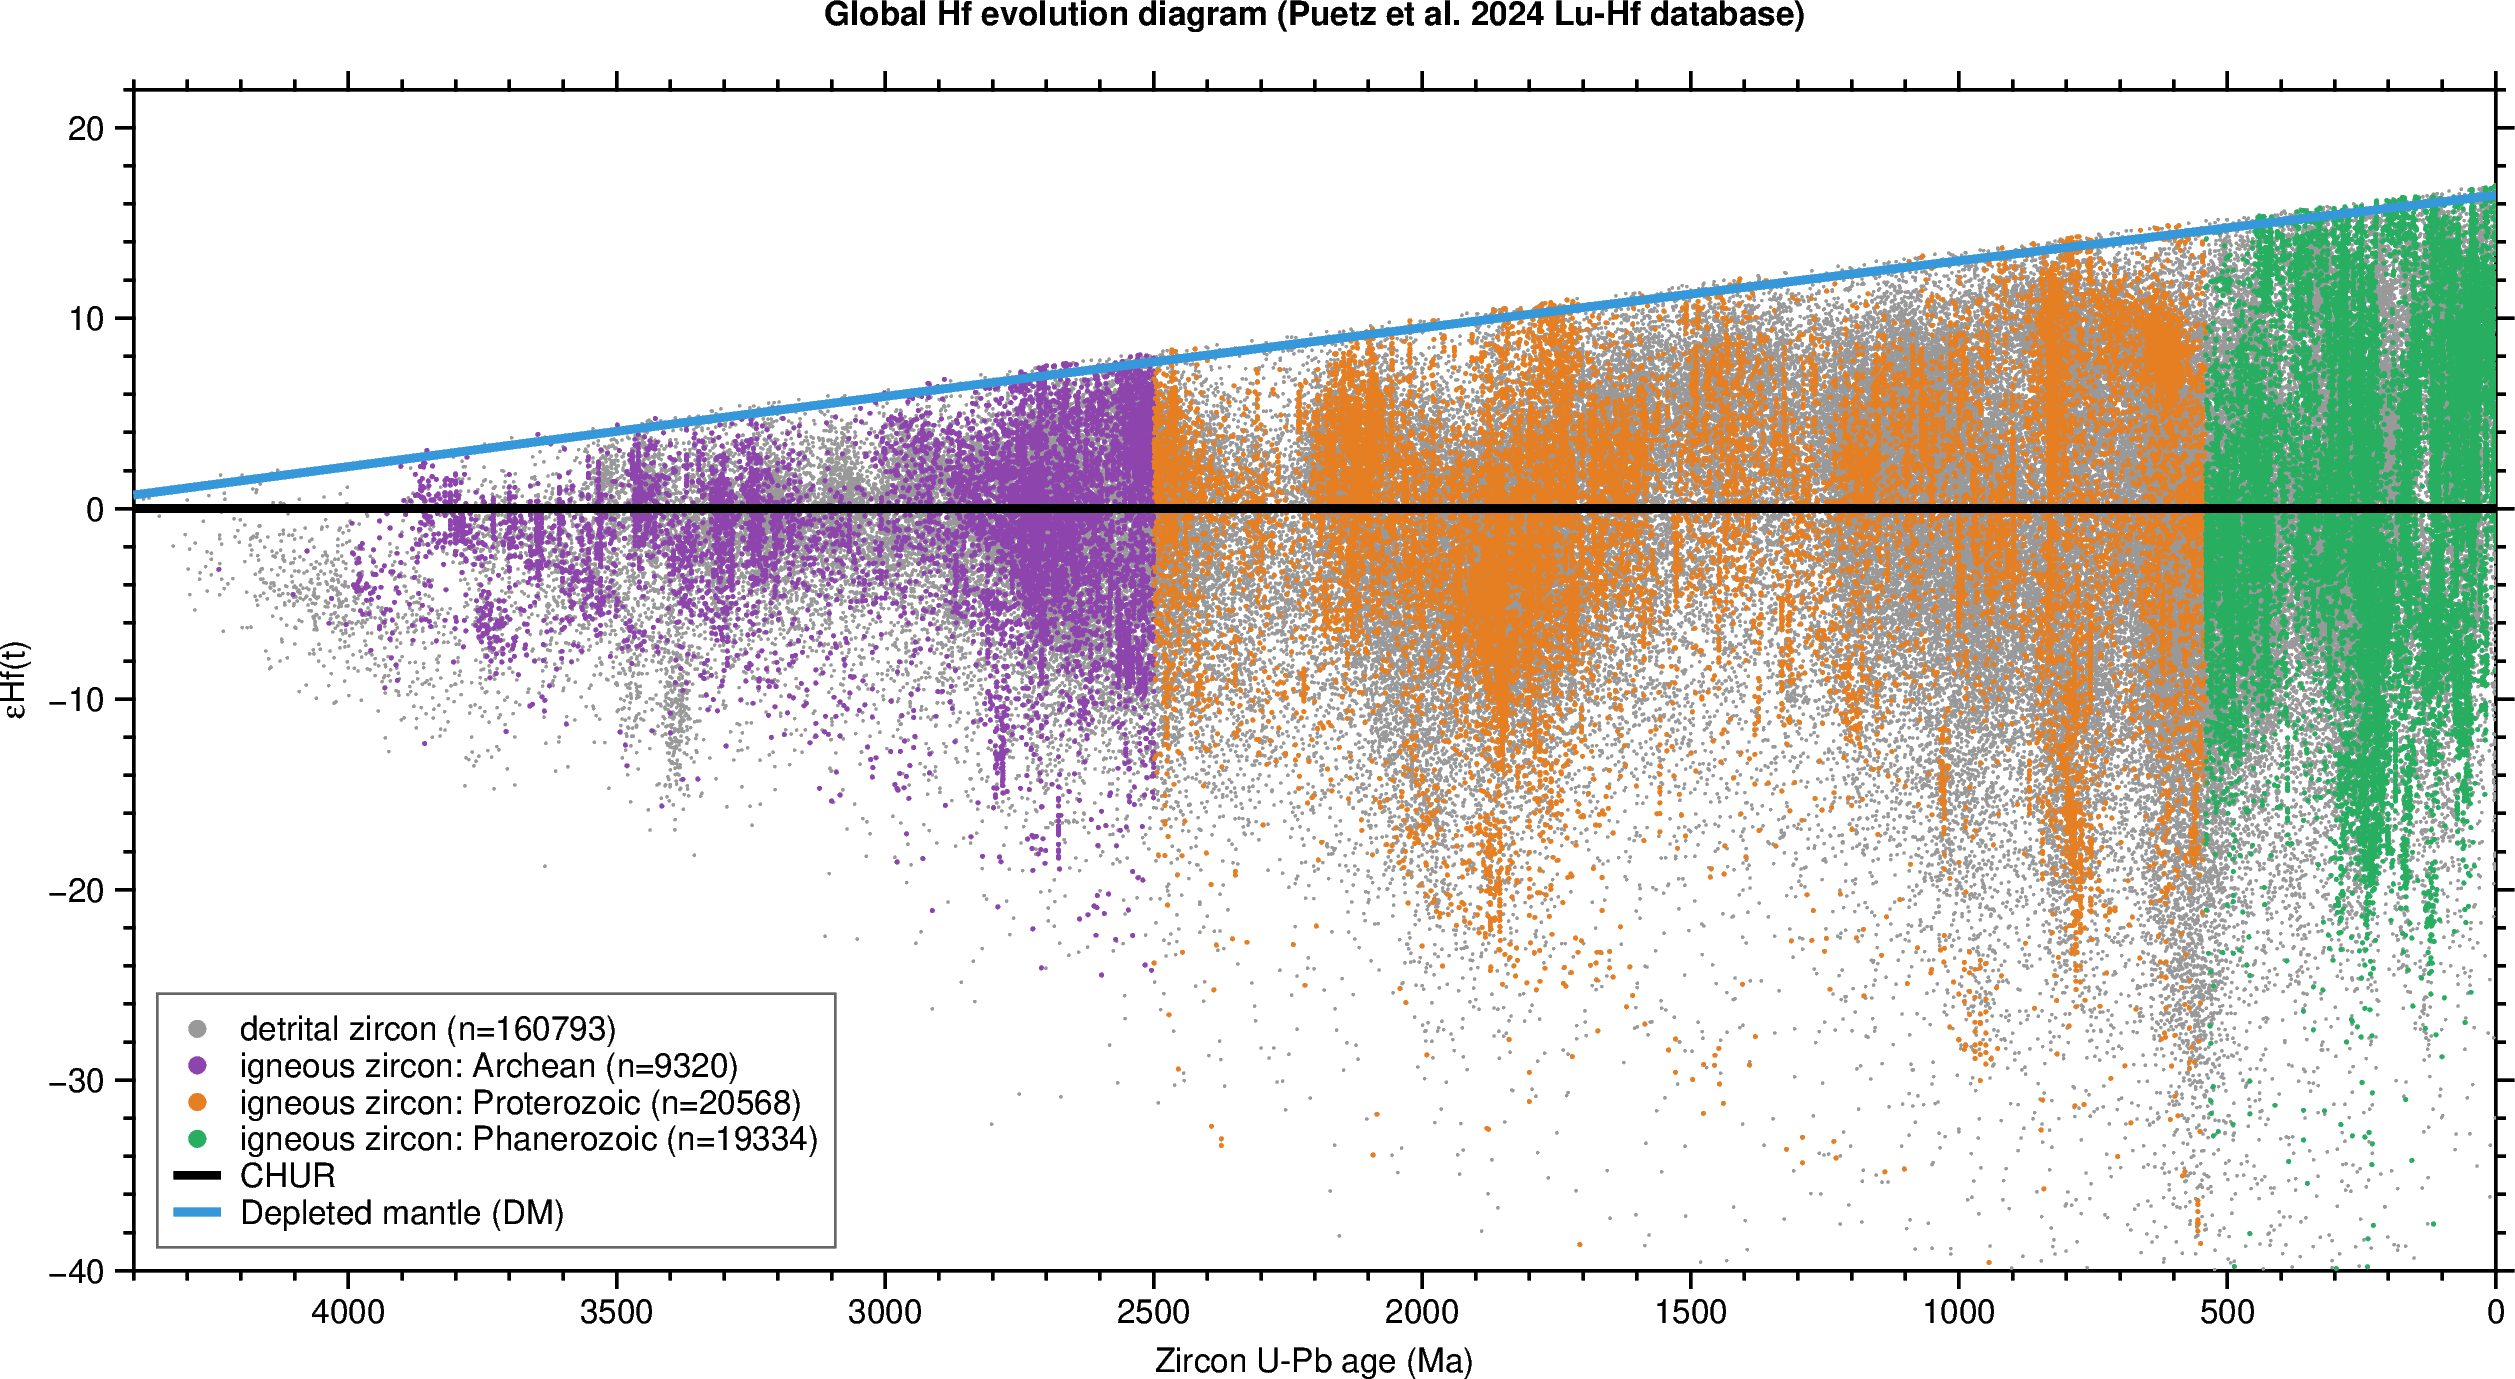

  292 analyses below εHf = -40 lie outside the plot


In [8]:
def epsilon_hf_at_time(hf177_today, lu177_today, t_ma):
    """εHf(t) of a reservoir with present-day (176Hf/177Hf, 176Lu/177Hf), evolved back to t Ma."""
    t_yr = t_ma * 1e6
    hf_ratio_t   = hf177_today - lu177_today * (np.exp(LAMBDA_176LU * t_yr) - 1)
    chur_ratio_t = CHUR_176HF_177HF_TODAY - CHUR_176LU_177HF_TODAY * (np.exp(LAMBDA_176LU * t_yr) - 1)
    return 1e4 * (hf_ratio_t / chur_ratio_t - 1)

ages_line = np.linspace(0, 4400, 441)
dm_line   = epsilon_hf_at_time(DM_176HF_177HF_TODAY, DM_176LU_177HF_TODAY, ages_line)

fig = pygmt.Figure()
fig.basemap(region=[0, 4400, -40, 22], projection="X-20c/10c",
            frame=["WSne+tGlobal Hf evolution diagram (Puetz et al. 2024 Lu-Hf database)",
                   "xa500f100+lZircon U-Pb age (Ma)", "yaf+lεHf(t)"])
det = grains[grains["rock_class"] == "detrital"]
fig.plot(x=det["age_ma"], y=det["eps_hf_t"], style="c0.025c", fill="gray60",
         label=f"detrital zircon (n={len(det)})+S0.15c")
ign = grains[grains["rock_class"] == "igneous"]
for lo, hi, colour, name in [(2500, 4500, "#8e44ad", "Archean"), (541, 2500, "#e67e22", "Proterozoic"),
                             (0, 541, "#27ae60", "Phanerozoic")]:
    sub = ign[(ign["age_ma"] >= lo) & (ign["age_ma"] < hi)]
    fig.plot(x=sub["age_ma"], y=sub["eps_hf_t"], style="c0.04c", fill=colour,
             label=f"igneous zircon: {name} (n={len(sub)})+S0.15c")
fig.plot(x=[0, 4400], y=[0, 0], pen="2p,black", label="CHUR")
fig.plot(x=ages_line, y=dm_line, pen="2p,#3498db", label="Depleted mantle (DM)")
fig.legend(position="JBL+jBL+o0.2c/0.2c", box="+gwhite+p0.5p,gray40")
fig.show(width=1100)
print(f"  {int((grains['eps_hf_t'] < -40).sum())} analyses below εHf = -40 lie outside the plot")

### How to read the Hf evolution diagram

- **Juvenile zircons plot near the DM line** (blue); **zircons of reworked crust plot below CHUR** (black). Values above the DM line can arise from analytical uncertainty or the choice of DM reference values.
- **The lower envelope** of the cloud slopes down towards young ages: re-melted old crust evolves along a Lu/Hf-controlled path below CHUR, so the oldest crust gives the most negative εHf(t) when it is reworked.
- **The vertical spread at any age** measures the diversity of crustal sources feeding new zircons at that time. Compare intervals of supercontinent assembly, when much old crust was reworked, with intervals dominated by juvenile additions.
- **Detrital and igneous zircons** cover the same field: detrital grains sample the eroded crust at large, igneous grains the crust at known places.


## Extend this

- **εNd(t) map.** Colour the whole-rock samples by `eps_nd_t` instead of T_DM2 — the Nd counterpart of §3.
- **Grain-level maps.** Join `hf_zircon_grains` to `hf_zircon_samples` on `sample_key` to map, for example, the fraction of zircons in each detrital sample with εHf(t) > 0.
- **Vary the paleo-age window.** Change `PALEO_WINDOW_MIN_MA / MAX_MA / PALEO_TARGET_MA` to isolate other crust-forming episodes: 1050-1250 Ma at 1100 Ma for Grenville-age crust, 1750-1950 Ma at 1850 Ma for Paleoproterozoic orogens, 90-120 Ma at 100 Ma for Cretaceous Cordilleran magmatism.
- **Compare with the zircon suite (D01-D04).** The Wu et al. (2023) zircon compilation of D01-D04 has U-Pb ages but no isotopes; the Puetz Hf database adds the isotopic dimension.
- **Weight by area.** Puetz et al. (2024) give a 12 x 12 degree grid weight for each sample (in the original workbooks) to offset the uneven sampling seen in §3.

## Related notebooks

- **D01-D04** — Wu 2023 zircon compilation (age only, no isotopes). D05 is the isotope companion.
- **G10** — Ophiolite-bearing sutures on the same kind of paleogeographic reconstruction.
- **I05** — PBDB paleobiogeography — same per-sample reconstruction pattern.

## Sources

- Puetz, S.J., Spencer, C.J., Condie, K.C. & Roberts, N.M.W. (2024). Enhanced U-Pb detrital zircon, Lu-Hf zircon, δ18O zircon, and Sm-Nd whole rock global databases. *Scientific Data* 11, 56. https://doi.org/10.1038/s41597-023-02902-9 — data: https://doi.org/10.6084/m9.figshare.24852987 (CC BY 4.0)
- Belousova, E.A., Kostitsyn, Y.A., Griffin, W.L., Begg, G.C., O'Reilly, S.Y. & Pearson, N.J. (2010). The growth of the continental crust: Constraints from zircon Hf-isotope data. *Lithos* 119, 457-466. doi:10.1016/j.lithos.2010.07.024.
- Roberts, N.M.W. & Spencer, C.J. (2015). The zircon archive of continent formation through time. *Geological Society, London, Special Publications* 389, 197-225. doi:10.1144/SP389.14.
- Bennett, V.C. & DePaolo, D.J. (1987). Proterozoic crustal history of the western United States as determined by neodymium isotopic mapping. *GSA Bulletin* 99(5), 674-685.
- Griffin, W.L., Pearson, N.J., Belousova, E., Jackson, S.E., van Achterbergh, E., O'Reilly, S.Y. & Shee, S.R. (2000). The Hf isotope composition of cratonic mantle: LAM-MC-ICPMS analysis of zircon megacrysts in kimberlites. *Geochimica et Cosmochimica Acta* 64(1), 133-147.
- Bouvier, A., Vervoort, J.D. & Patchett, P.J. (2008). The Lu-Hf and Sm-Nd isotopic composition of CHUR: Constraints from unequilibrated chondrites and implications for the bulk composition of terrestrial planets. *EPSL* 273, 48-57.
- Cao, X., Collins, A.S., Pisarevsky, S., Flament, N., Li, S., Hasterok, D. & Müller, R.D. (2024). Earth's tectonic and plate boundary evolution over 1.8 billion years. *Geoscience Frontiers* 15(6), 101922. doi:10.1016/j.gsf.2024.101922.